# Create Universe and Filings Tables

The Universe table will contain the information of each company.  
The Filings table will contain the information of each report.  
  
*Note: A reduced list of companies will be used in this notebook for the pilot*

### Setup

In [1]:
import os
from time import sleep
import json
from pathlib import Path

import pandas as pd
import numpy as np
import requests
import yfinance as yf
import matplotlib.pyplot as plt

from dotenv import load_dotenv

from volatility_from_text.data.align_filings_to_market import first_tradable_date

In [2]:
ROOT = Path.cwd().parent          # One step back
BRONZE = ROOT / "data" / "bronze"
SILVER = ROOT / "data" / "silver"

# Create de directories for bronces and silver data layers
BRONZE.mkdir(parents=True, exist_ok=True)
SILVER.mkdir(parents=True, exist_ok=True)


# Start and end dates of the period evaluated for the reports 
START = "2010-01-01"
END = "2019-12-31"

# Price timeseries
START_PRICES = pd.to_datetime(START) - pd.DateOffset(years=1)
END_PRICES = pd.to_datetime(END) + pd.DateOffset(months=2)

ROUTE_PRICES = BRONZE / "prices"
ROUTE_PRICES.mkdir(parents=True, exist_ok=True)

load_dotenv()
HEADERS = {"User-Agent": os.environ["SEC_USER_AGENT"] } # SEC requires identification to access their data

# Note: This list was provided by a LLM
CANDIDATES = {
    "Technology": ["AAPL", "MSFT", "INTC", "CSCO", "ORCL", "IBM", "QCOM", "TXN", "ADBE", "NVDA", "AMD", "HPQ", "MU", "AMAT", "ADI"],
    "Financials": ["JPM", "BAC", "WFC", "C", "GS", "MS", "USB", "PNC", "AXP", "BNY", "STT", "COF", "MET", "PRU", "TRV"],
    "Utilities":  ["DUK", "SO", "NEE", "D", "AEP", "EXC", "XEL", "ED", "PEG", "WEC", "ES", "DTE", "ETR", "PPL", "FE"],
}

## EDA

In [3]:
# List comprehension to build the dataframe, easier to use than a list
df_candidates = pd.DataFrame(
    [(sector, ticker) for sector, tickers in CANDIDATES.items() for ticker in tickers],
    columns=["sector", "ticker"]
)

df_candidates.head() 

,sector,ticker
0,Technology,AAPL
1,Technology,MSFT
2,Technology,INTC
3,Technology,CSCO
4,Technology,ORCL


In [4]:
df_candidates.info()

<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   sector  45 non-null     str  
 1   ticker  45 non-null     str  
dtypes: str(2)
memory usage: 1.4 KB


In [5]:
def get_json(url: str, path: Path, headers: dict[str, str] = HEADERS) -> dict:
    """
    Read a JSON from disk if cached; otherwise download it and save it.

    Parameters
    ----------
    url : str
        URL of the JSON to download.
    path : pathlib.Path
        Local cache file.
    headers : dict[str, str]
        HTTP headers (SEC User-Agent).

    Returns
    -------
    dict
        Parsed JSON.
    """
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    r = requests.get(url, headers=headers, timeout=30)
    r.raise_for_status()
    sleep(0.15)                       # SEC limit: 10 requests per second
    path.write_text(r.text, encoding="utf-8")
    return r.json()

In [6]:
CIK_ROUTE = BRONZE / "company_tickers.json"
url = "https://www.sec.gov/files/company_tickers.json"
dict_cik = get_json(url=url, path=CIK_ROUTE)
print(f"Data type downloaded: {type(dict_cik)}")

Data type downloaded: <class 'dict'>


In [7]:
list(dict_cik.values())[:5]

[{'cik_str': 320193, 'ticker': 'AAPL', 'title': 'Apple Inc.'},
 {'cik_str': 1045810, 'ticker': 'NVDA', 'title': 'NVIDIA CORP'},
 {'cik_str': 789019, 'ticker': 'MSFT', 'title': 'MICROSOFT CORP'},
 {'cik_str': 1652044, 'ticker': 'GOOGL', 'title': 'Alphabet Inc.'},
 {'cik_str': 1018724, 'ticker': 'AMZN', 'title': 'AMAZON COM INC'}]

In [8]:
df_cik = pd.DataFrame(list(dict_cik.values()))
df_cik.head()

,cik_str,ticker,title
0,320193,AAPL,Apple Inc.
1,1045810,NVDA,NVIDIA CORP
2,789019,MSFT,MICROSOFT CORP
3,1652044,GOOGL,Alphabet Inc.
4,1018724,AMZN,AMAZON COM INC


In [9]:
df_cik.info()

<class 'pandas.DataFrame'>
RangeIndex: 10404 entries, 0 to 10403
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   cik_str  10404 non-null  int64
 1   ticker   10404 non-null  str  
 2   title    10404 non-null  str  
dtypes: int64(1), str(2)
memory usage: 516.9 KB


In [10]:
# Join our companies with their cik
df = df_candidates.merge(df_cik, how="left", on="ticker")
df.head()

,sector,ticker,cik_str,title
0,Technology,AAPL,320193,Apple Inc.
1,Technology,MSFT,789019,MICROSOFT CORP
2,Technology,INTC,50863,INTEL CORP
3,Technology,CSCO,858877,"CISCO SYSTEMS, INC."
4,Technology,ORCL,1341439,ORACLE CORP


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   sector   45 non-null     str  
 1   ticker   45 non-null     str  
 2   cik_str  45 non-null     int64
 3   title    45 non-null     str  
dtypes: int64(1), str(3)
memory usage: 2.9 KB


In [12]:
# Improved version of the edgar_filings function of the first notebook which already filters for 10-k form

def ten_k_filings(
    ciks: pd.Series,
    companies: pd.Series,
    tickers: pd.Series,
    sectors: pd.Series,
    route: Path = BRONZE,
    start: str = START,
    end: str = END,
    headers: dict[str, str] = HEADERS,
) -> pd.DataFrame:
    """
    Return the 10-K filings of each company between `start` and `end`.

    Parameters
    ----------
    ciks : pandas.Series
        Company CIKs.
    companies : pandas.Series
        Company names, aligned with `ciks`.
    tickers : pandas.Series
        Tickers, aligned with `ciks`.
    sectors : pandas.Series
        Pilot sectors, aligned with `ciks`.
    route : pathlib.Path
        Bronze folder where the SEC submissions JSONs are cached.
    start : str
        First filing date included (YYYY-MM-DD).
    end : str
        Last filing date included (YYYY-MM-DD).
    headers : dict[str, str]
        HTTP headers (SEC User-Agent).

    Returns
    -------
    pandas.DataFrame
        One row per 10-K, with company info (SIC, fiscal year end).
    """
    base = "https://data.sec.gov/submissions/"
    folder = route / "submissions"
    folder.mkdir(parents=True, exist_ok=True)   # creates the directory if needed

    all_filings = []

    for cik, company, ticker, sector in zip(ciks, companies, tickers, sectors):
        # main JSON: company info + the newest ~1000 filings + names of the older pages
        name = f"CIK{cik:010d}.json"            # company index padded to 10 digits
        data = get_json(base + name, folder / name, headers)

        pages = [pd.DataFrame(data["filings"]["recent"])]

        # older pages: only those whose date range overlaps [start, end]
        for page in data["filings"]["files"]:
            if page["filingTo"] >= start and page["filingFrom"] <= end:
                old = get_json(base + page["name"], folder / page["name"], headers)
                pages.append(pd.DataFrame(old))   # same columns as "recent"

        # recent + old pages in one DataFrame, with the company data
        cik_filings = pd.concat(pages, ignore_index=True).assign(
            cik=cik, 
            ticker=ticker, 
            company=company, 
            sector=sector,
            sic=data["sic"],  # Standard Industrial Classification, same info as sector but too detailed (4 digit id)
            sic_description=data["sicDescription"], # Title of the sic, human reading only
            fiscal_year_end=data["fiscalYearEnd"],
        )
        all_filings.append(cik_filings)

    filings = pd.concat(all_filings, ignore_index=True)

    # Keep 10-K forms between start and end
    filings = filings[
          (filings["filingDate"] >= start)
        & (filings["filingDate"] <= end)
        & (filings["form"] == "10-K")
    ]
    return filings.reset_index(drop=True)

In [13]:
ten_k = ten_k_filings(ciks=df['cik_str'], companies=df['title'], tickers=df['ticker'], sectors=df["sector"])
ten_k.head()

,accessionNumber,filingDate,reportDate,acceptanceDateTime,act,form,fileNumber,filmNumber,items,core_type,...,isXBRLNumeric,primaryDocument,primaryDocDescription,cik,ticker,company,sector,sic,sic_description,fiscal_year_end
0,0000320193-19-000119,2019-10-31,2019-09-28,2019-10-30T22:12:36.000Z,34,10-K,001-36743,191181423,,XBRL,...,NaN,a10-k20199282019.htm,10-K,320193,AAPL,Apple Inc.,Technology,3571,Electronic Computers,0926
1,0000320193-18-000145,2018-11-05,2018-09-29,2018-11-05T13:01:40.000Z,34,10-K,001-36743,181158788,,10-K,...,NaN,a10-k20189292018.htm,10-K,320193,AAPL,Apple Inc.,Technology,3571,Electronic Computers,0926
2,0000320193-17-000070,2017-11-03,2017-09-30,2017-11-03T12:01:37.000Z,34,10-K,001-36743,171174673,,10-K,...,NaN,a10-k20179302017.htm,10-K,320193,AAPL,Apple Inc.,Technology,3571,Electronic Computers,0926
3,0001628280-16-020309,2016-10-26,2016-09-24,2016-10-26T20:42:16.000Z,34,10-K,001-36743,161953070,,10-K,...,NaN,a201610-k9242016.htm,10-K,320193,AAPL,Apple Inc.,Technology,3571,Electronic Computers,0926
4,0001193125-15-356351,2015-10-28,2015-09-26,2015-10-28T20:31:09.000Z,34,10-K,001-36743,151180619,,10-K,...,NaN,d17062d10k.htm,FORM 10-K,320193,AAPL,Apple Inc.,Technology,3571,Electronic Computers,0926


In [14]:
ten_k.info()

<class 'pandas.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   accessionNumber        450 non-null    str   
 1   filingDate             450 non-null    str   
 2   reportDate             450 non-null    str   
 3   acceptanceDateTime     450 non-null    str   
 4   act                    450 non-null    str   
 5   form                   450 non-null    str   
 6   fileNumber             450 non-null    str   
 7   filmNumber             450 non-null    str   
 8   items                  450 non-null    str   
 9   core_type              450 non-null    str   
 10  size                   450 non-null    int64 
 11  isXBRL                 450 non-null    int64 
 12  isInlineXBRL           450 non-null    int64 
 13  isXBRLNumeric          0 non-null      object
 14  primaryDocument        450 non-null    str   
 15  primaryDocDescription  450 non-nul

In [15]:
# print each dintinct sic grouped by the custom sector (one per company)
ten_k.drop_duplicates("cik").groupby("sector")["sic_description"].value_counts()

sector      sic_description                                   
Financials  National Commercial Banks                             7
            Security Brokers, Dealers & Flotation Companies       2
            State Commercial Banks                                2
            Life Insurance                                        2
            Finance Services                                      1
            Fire, Marine & Casualty Insurance                     1
Technology  Semiconductors & Related Devices                      7
            Services-Prepackaged Software                         3
            Computer & office Equipment                           2
            Electronic Computers                                  1
            Computer Communications Equipment                     1
            Radio & Tv Broadcasting & Communications Equipment    1
Utilities   Electric Services                                     9
            Electric & Other Services Combined       

**Findings**  
There are 14 distinct SIC categories within the three right sectors, no cleaning needed

## Data Cleaning & Feature Engineering

In [16]:
ten_k = ten_k.rename(columns={"cik_str":"cik"})
ten_k.columns

Index(['accessionNumber', 'filingDate', 'reportDate', 'acceptanceDateTime',
       'act', 'form', 'fileNumber', 'filmNumber', 'items', 'core_type', 'size',
       'isXBRL', 'isInlineXBRL', 'isXBRLNumeric', 'primaryDocument',
       'primaryDocDescription', 'cik', 'ticker', 'company', 'sector', 'sic',
       'sic_description', 'fiscal_year_end'],
      dtype='str')

In [17]:
# Convert to datetime for year filtering and future convenience
ten_k["filingDate"] = pd.to_datetime(ten_k["filingDate"])
ten_k["reportDate"] = pd.to_datetime(ten_k["reportDate"])

# Convert to datetime keeping the utc timezone. Does not matter for first_tradable_date but it is usefull later
ten_k["acceptanceDateTime"] = pd.to_datetime(ten_k["acceptanceDateTime"], utc=True)

In [18]:
# One 10-K per company and year: build the company x year table
table = ten_k.groupby(["cik", ten_k["filingDate"].dt.year]).size().unstack(fill_value=0)

# Companies with exactly one report in every year
complete = table.index[(table == 1).all(axis=1)]

# Report and drop the rest
dropped = table.index.difference(complete)
ten_k = ten_k[ten_k["cik"].isin(complete)]

print(f"{len(complete)} companies kept, {len(dropped)} dropped: {list(dropped)}")

45 companies kept, 0 dropped: []


In [19]:
def remove_duplicates_in_a_year(
    df: pd.DataFrame, cik_col: str, filing_date_col: str
) -> tuple[pd.DataFrame, pd.Index]:
    """
    Keep only the companies with exactly one filing in every year.

    Parameters
    ----------
    df : pandas.DataFrame
        Filings, one row per report.
    cik_col : str
        Name of the company identifier column.
    filing_date_col : str
        Name of the filing date column (datetime dtype).

    Returns
    -------
    pandas.DataFrame
        Filings of the companies kept.
    pandas.Index
        Identifiers of the companies dropped.
    """
    # One 10-K per company and year: build the company x year table
    table = df.groupby([cik_col, df[filing_date_col].dt.year]).size().unstack(fill_value=0)

    # Companies with exactly one report in every year
    complete = table.index[(table == 1).all(axis=1)]

    # Report and drop the rest
    dropped = table.index.difference(complete)

    print(f"{len(complete)} companies kept, {len(dropped)} dropped: {list(dropped)}")

    df = df[df[cik_col].isin(complete)]

    return df, dropped


In [20]:
ten_k, dropped = remove_duplicates_in_a_year(df=ten_k, cik_col="cik", filing_date_col="filingDate")

45 companies kept, 0 dropped: []


In [21]:
def get_prices(
    ticker: str,
    start: pd.Timestamp = START_PRICES,
    end: pd.Timestamp = END_PRICES,
    route_prices: Path = ROUTE_PRICES,
) -> pd.DataFrame:
    """
    Load adjusted daily prices from the parquet cache or download them from yfinance.

    Parameters
    ----------
    ticker : str
        Yahoo Finance ticker.
    start : pandas.Timestamp
        First date downloaded.
    end : pandas.Timestamp
        End date of the download (exclusive).
    route_prices : pathlib.Path
        Folder of the parquet cache.

    Returns
    -------
    pandas.DataFrame
        Daily OHLCV prices indexed by date.
    """
    
    if (route_prices / f"{ticker}.parquet").exists():
        df = pd.read_parquet(route_prices / f"{ticker}.parquet")
    else:
        df = yf.download(tickers=ticker, start=start, end=end, auto_adjust=True, progress=False)
        df.columns = df.columns.get_level_values(0)
        df.to_parquet(route_prices / f"{ticker}.parquet")

    return df

*Note: Parquet keeps data type and compresses the data while csv does not do either*

In [22]:
# SP500 index fund to determine if the market is or not closed
sp500 = get_prices("SPY")
sp500.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2009-01-02,67.638626,67.987881,65.375759,65.805051,227566300
2009-01-05,67.558571,68.147939,66.860066,67.398496,240349700
2009-01-06,68.009689,68.722744,67.434877,68.133382,328260900
2009-01-07,65.972404,67.129307,65.630427,66.940127,280899200
2009-01-08,66.241623,66.278000,65.244795,65.601328,263834400


In [23]:
SESSIONS = sp500.index
SESSIONS[:5]

DatetimeIndex(['2009-01-02', '2009-01-05', '2009-01-06', '2009-01-07',
               '2009-01-08'],
              dtype='datetime64[ms]', name='Date', freq=None)

In [ ]:
def check_session(df: pd.DataFrame, ticker: str, sessions: pd.DatetimeIndex = SESSIONS) -> bool:
    """
    Check that a price table has exactly the same trading days as the SPY calendar.

    Parameters
    ----------
    df : pandas.DataFrame
        Daily prices indexed by date.
    ticker : str
        Ticker, used in the warning message.
    sessions : pandas.DatetimeIndex
        Reference trading sessions (SPY).

    Returns
    -------
    bool
        True if the calendars match.
    """
    if (df.index.equals(sessions)):
        return True
    else:
        print(f"{ticker} does not have the same calendar as the sp500")
        return False

In [ ]:
for ticker in ten_k["ticker"].unique(): # Tickers are repeated each year, just use it once
    df = get_prices(ticker = ticker) # Import prices form yfinance or data/bronze/prices/ticker.parquet 
    if not (check_session(df = df, ticker = ticker)): # If the ticker has sessions missing or extra compared de SPY it is removed
        ten_k = ten_k[ten_k["ticker"] != ticker]

ten_k["ticker"].info()

<class 'pandas.Series'>
RangeIndex: 450 entries, 0 to 449
Series name: ticker
Non-Null Count  Dtype
--------------  -----
450 non-null    str  
dtypes: str(1)
memory usage: 5.0 KB


**Findings**  
 - All 45 companies where successfully imported
 - Every companies had the same session calendar as the Sp500 fund

Because there are more than 10 survivors per sector, 5 of the 15 will be eliminated at random

In [26]:
np.random.seed(27)

chosen_companies = []
for sector in df_candidates["sector"].unique():
   chosen_companies  += list(df_candidates[df_candidates["sector"]==sector]["ticker"].sample(n=10).values)

print("Chosen companies:")    
print(chosen_companies)

Chosen companies:
['AMD', 'QCOM', 'ORCL', 'ADI', 'INTC', 'TXN', 'NVDA', 'MSFT', 'HPQ', 'IBM', 'COF', 'PNC', 'MET', 'PRU', 'AXP', 'MS', 'JPM', 'WFC', 'BNY', 'C', 'WEC', 'AEP', 'PPL', 'D', 'DUK', 'FE', 'SO', 'EXC', 'PEG', 'DTE']


In [27]:
len(chosen_companies)

30

In [28]:
ten_k = ten_k[ten_k["ticker"].isin(chosen_companies)]
ten_k = ten_k.reset_index(drop=True)

In [29]:
ten_k["first_tradable_date"] = [first_tradable_date(accepted_at = acceptance, sessions = SESSIONS) for acceptance in ten_k["acceptanceDateTime"]]
ten_k["first_tradable_date"].head()

0    2019-08-02
1    2018-08-06
2    2017-08-03
3    2016-07-29
4    2015-08-03
Name: first_tradable_date, dtype: object

### Feature Exploration & Validation.

In [30]:
ten_k["cik"].count()

np.int64(300)

**Findings**  
Exactly the *number of companies* x *years* (30 x 10)

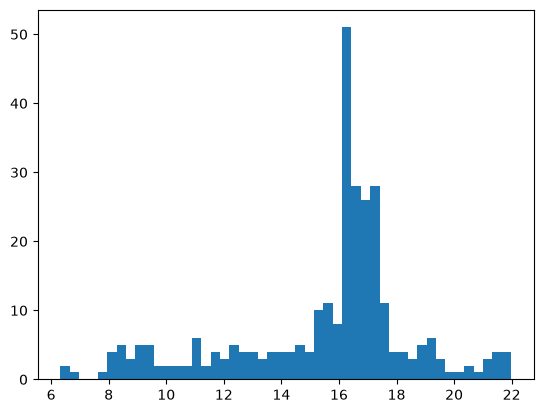

In [31]:
# Histogram of the moment a report gets accepted
ny = ten_k["acceptanceDateTime"].dt.tz_convert("America/New_York") # Convert to NY timestamp due to the hour offset
plt.hist(ny.dt.hour + ny.dt.minute / 60, bins=48);

**Findings**  
 - Most of the companies get their report accepted shortly after the session closes at 4pm

In [32]:
# Share accepted with the market closed
t = ny.dt.hour + ny.dt.minute / 60
((t < 9.5) | (t >= 16)).mean()

np.float64(0.7133333333333334)

**Findings**  
 - 71.33% of the reports are accepted with the market closed, hence validating the histogram

In [33]:
ten_k["filingDate"] = pd.to_datetime(ten_k["filingDate"])
ten_k["first_tradable_date"] = pd.to_datetime(ten_k["first_tradable_date"])

# Percentage of first tradable dates equal from their fling dates
(ten_k["first_tradable_date"] == ten_k["filingDate"]).sum() / ten_k["first_tradable_date"].count() * 100

np.float64(22.666666666666664)

**Findings**  
 - Only 22.66% of dates coincide, meaning that ignoring the 4-5 hour shift would have produced to take into account a session that ended before the release of the report.

In [34]:
# Distinct weeks with at least one report
ten_k["first_tradable_date"].dt.to_period("W").nunique()

97

**Findings**  
 - The 300 reports along 521 weeks were concentrated in just 97 weeks

## Save Data

In [35]:
# 1 row per company, describes the company
UNIVERSE_COLS = ["cik", "ticker", "company", "sector", "sic", "sic_description", "fiscal_year_end"]

universe = ten_k[UNIVERSE_COLS].drop_duplicates("cik").reset_index(drop=True)
universe.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   cik              30 non-null     int64
 1   ticker           30 non-null     str  
 2   company          30 non-null     str  
 3   sector           30 non-null     str  
 4   sic              30 non-null     str  
 5   sic_description  30 non-null     str  
 6   fiscal_year_end  30 non-null     str  
dtypes: int64(1), str(6)
memory usage: 3.7 KB


In [36]:
universe.to_parquet(SILVER / "universe.parquet")

In [37]:
# row per report, describes the report
FILINGS_COLS = ["cik", "accessionNumber", "form", "filingDate", "reportDate",
                "acceptanceDateTime", "first_tradable_date"]

filings = ten_k[FILINGS_COLS].reset_index(drop=True)

# rename columns for data consistency
filings = filings.rename(columns={
    "accessionNumber": "accession_number",
    "filingDate": "filing_date",
    "reportDate": "report_date",
    "acceptanceDateTime": "accepted_at_utc",
})

filings.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype              
---  ------               --------------  -----              
 0   cik                  300 non-null    int64              
 1   accession_number     300 non-null    str                
 2   form                 300 non-null    str                
 3   filing_date          300 non-null    datetime64[us]     
 4   report_date          300 non-null    datetime64[us]     
 5   accepted_at_utc      300 non-null    datetime64[us, UTC]
 6   first_tradable_date  300 non-null    datetime64[s]      
dtypes: datetime64[s](1), datetime64[us, UTC](1), datetime64[us](2), int64(1), str(2)
memory usage: 23.6 KB


In [38]:
filings.to_parquet(SILVER / "filings.parquet")